# 1. ¿Cuánto vale jugar en casa en LaLiga?

**Pregunta:** ¿qué ventaja da jugar como local y qué pasó cuando los estadios se quedaron vacíos por la COVID-19?

Entre junio de 2020 y junio de 2021 LaLiga se jugó sin público. Es un experimento natural: mismo campeonato, mismos equipos, pero sin afición. Si la ventaja local se debe sobre todo al público, debería reducirse en esos partidos.

Se usan solo temporadas terminadas (se excluye la temporada en curso).

In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MARTS, IMG = ROOT / "data" / "marts", ROOT / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
for t in ["fct_matches", "fct_standings_by_matchday", "fct_final_standings", "mart_home_advantage", "mart_comebacks"]:
    con.execute(f"create view {t} as select * from '{MARTS / (t + '.parquet')}'")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
q = lambda sql: con.execute(sql).df()

## Ventaja local por temporada

In [2]:
by_season = q("""
    select season,
           sum(matches) as partidos,
           sum(home_win_rate * matches) / sum(matches) as victoria_local,
           sum(draw_rate * matches) / sum(matches)     as empate,
           sum(away_win_rate * matches) / sum(matches) as victoria_visitante,
           sum(avg_home_points * matches) / sum(matches) - sum(avg_away_points * matches) / sum(matches) as ventaja_puntos
    from mart_home_advantage
    where season < (select max(season) from mart_home_advantage)  -- solo temporadas terminadas
    group by season order by season""")
by_season.style.format({"victoria_local": "{:.1%}", "empate": "{:.1%}", "victoria_visitante": "{:.1%}", "ventaja_puntos": "{:+.2f}"})

,season,partidos,victoria_local,empate,victoria_visitante,ventaja_puntos
0,2012-13,380.000000,49.7%,22.1%,28.2%,+0.65
1,2013-14,380.000000,47.1%,22.6%,30.3%,+0.51
2,2014-15,380.000000,45.0%,23.9%,31.1%,+0.42
3,2015-16,380.000000,48.2%,24.2%,27.6%,+0.62
4,2016-17,380.000000,47.6%,23.4%,28.9%,+0.56
5,2017-18,380.000000,47.1%,22.6%,30.3%,+0.51
6,2018-19,380.000000,44.2%,28.9%,26.8%,+0.52
7,2019-20,380.000000,45.8%,27.6%,26.6%,+0.58
8,2020-21,380.000000,41.6%,28.7%,29.7%,+0.36
9,2021-22,380.000000,43.4%,29.2%,27.4%,+0.48


## Con público frente a sin público

In [3]:
groups = q("""
    select case when is_behind_closed_doors then 'Sin público' else 'Con público' end as grupo,
           count(*) as partidos,
           avg((outcome = 'local')::int)     as victoria_local,
           avg((outcome = 'empate')::int)    as empate,
           avg((outcome = 'visitante')::int) as victoria_visitante,
           avg(case outcome when 'local' then 3 when 'empate' then 1 else 0 end)
         - avg(case outcome when 'visitante' then 3 when 'empate' then 1 else 0 end) as ventaja_puntos,
           avg(home_goals) - avg(away_goals) as ventaja_goles
    from fct_matches
    where season < (select max(season) from fct_matches)  -- solo temporadas terminadas
    group by 1 order by 1""")
groups.style.format({"victoria_local": "{:.1%}", "empate": "{:.1%}", "victoria_visitante": "{:.1%}",
                     "ventaja_puntos": "{:+.2f}", "ventaja_goles": "{:+.2f}"})

,grupo,partidos,victoria_local,empate,victoria_visitante,ventaja_puntos,ventaja_goles
0,Con público,4820,46.6%,25.0%,28.4%,+0.54,+0.41
1,Sin público,490,41.4%,28.4%,30.2%,+0.34,+0.22


### ¿Es una diferencia real o puede ser casualidad?

Usamos un test de diferencia de proporciones sobre el % de victorias locales. Solo hay unos 450 partidos sin público, así que conviene comprobarlo.

In [4]:
import math
a, b = groups.set_index("grupo").loc["Con público"], groups.set_index("grupo").loc["Sin público"]
p1, n1, p2, n2 = a.victoria_local, a.partidos, b.victoria_local, b.partidos
p = (p1 * n1 + p2 * n2) / (n1 + n2)
z = (p1 - p2) / math.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
p_value = math.erfc(abs(z) / math.sqrt(2))
print(f"Victoria local con público: {p1:.1%} (n={n1:.0f})")
print(f"Victoria local sin público: {p2:.1%} (n={n2:.0f})")
print(f"Diferencia: {(p1 - p2) * 100:.1f} puntos porcentuales · z = {z:.2f} · p-valor = {p_value:.3f}")

Victoria local con público: 46.6% (n=4820)
Victoria local sin público: 41.4% (n=490)
Diferencia: 5.1 puntos porcentuales · z = 2.17 · p-valor = 0.030


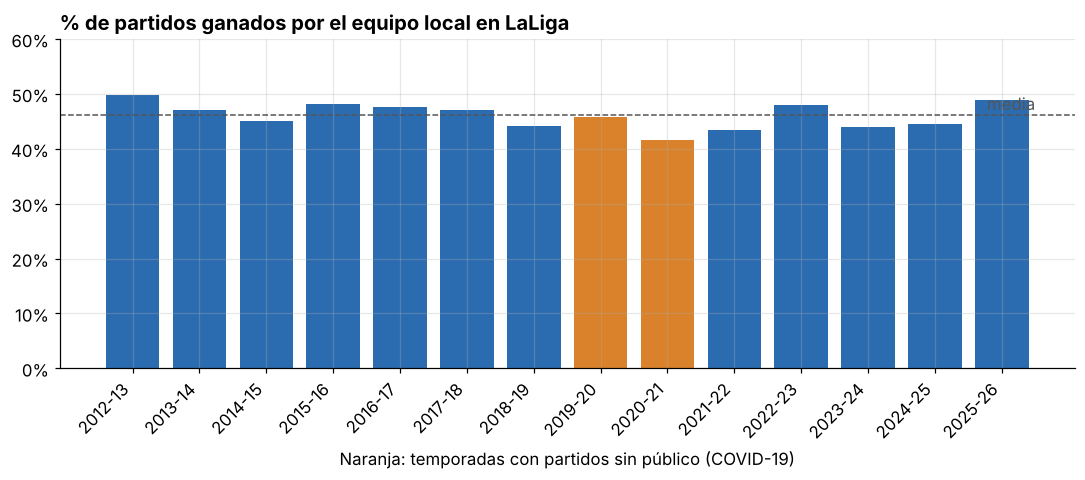

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cols = ["#d9822b" if s in ("2019-20", "2020-21") else "#2b6cb0" for s in by_season.season]
ax.bar(by_season.season, by_season.victoria_local, color=cols)
ax.axhline(by_season.victoria_local.mean(), color="#555", ls="--", lw=1)
ax.set_ylim(0, .6); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("% de partidos ganados por el equipo local en LaLiga", loc="left", fontweight="bold")
ax.text(len(by_season) - .5, by_season.victoria_local.mean() + .01, "media", ha="right", color="#555")
ax.set_xlabel("Naranja: temporadas con partidos sin público (COVID-19)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
fig.savefig(IMG / "ventaja_local.png", dpi=150); plt.show()

## Conclusiones

- Jugar en casa da ventaja en todas las temporadas: con público, el local gana el **46,6 %** de los partidos y el visitante el 28,4 %.
- Sin público (490 partidos), la victoria local baja al **41,4 %** y el margen medio de goles del local casi se reduce a la mitad (de +0,41 a +0,22).
- La diferencia es estadísticamente significativa al 5 % (p ≈ 0,03), pero por poco. La ventaja **se reduce, no desaparece**: parte de ella viene de otros factores (no viajar, conocer el campo, rutinas).
- Prudencia: esos partidos coinciden con un calendario anómalo (partidos cada tres días tras el parón), que también pudo influir.